In [1]:
import ot
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import MiniBatchKMeans
import math
import scipy
from scipy.spatial import cKDTree
from scipy import integrate
from scipy import interpolate
from scipy.spatial import Delaunay
from scipy.spatial import Voronoi
from itertools import product
import torch
torch.manual_seed(100000)
import torch.nn as nn
import torch.optim as optim
import pysindy as ps
from torchdiffeq import odeint


/homes/yinonghyn/.local/lib/python3.10/site-packages/pysindy/feature_library/base.py:40: DeprecationWarning: Library ensembling is no longer performed by feature libraries.  Use EnsemblingOptimizer to fit an ensemble model.
  warnings.warn(


In [2]:
#settings
start = np.array((0., 1., 1.05))
dt = 0.01
subset_size = 100#50 #cell number
slope = 2#2 #parameter in weight computation
traj_length = int(1e6)#length of trajectory
noise_level = 0#0.3#.9#0.8
sample_size = int(10000)#int(subset_size*50)
epsilon = 1e-4
simulation_t = int(5e4)
# Define the Lorenz-63 System
def Lorenz(x):
    x = x.T
    dx = 10 * (x[1] - x[0])
    dy = x[0] * (28 - x[2]) - x[1]
    dz = x[0] * x[1] - (8/3) * x[2]
    f = np.array((dx, dy, dz)).T
    return f

 #trajectory simulation (Euler's method)
def traj(length, starts = start, model = Lorenz):
    x = starts
    traj = np.zeros((length,len(starts)))
    traj[0] = np.array(x)
    for timestep in range(length-1):

        x = x + dt * model(x)

        traj[timestep+1] = np.array(x)

    return traj

def invariant_measure(matrix):
    N = len(matrix)
    rhs = (-1) * (epsilon/N) * torch.ones(N)
    rho = torch.linalg.solve(((1 - epsilon) * matrix - torch.eye(N)),rhs)
    return rho

In [3]:
trajectory_clean = traj(traj_length)

In [4]:
trajectory = trajectory_clean + np.random.normal(0,noise_level,((traj_length,3)))#loooooooong trajectory
trajectory = trajectory[int(1e4):]

#a random chuck of data
rand_start = np.random.randint(1, len(trajectory)-sample_size)
randpts = torch.tensor(trajectory[rand_start:rand_start+sample_size],dtype = torch.float)
Trandpts = torch.tensor(trajectory[rand_start+1:rand_start+1+sample_size],dtype = torch.float)

#normalization
M_scale = torch.max(torch.abs(randpts))
randpts /= M_scale
Trandpts /= M_scale

#Voronoi cell center
Voronoi_centers = MiniBatchKMeans(n_clusters=subset_size).fit(randpts).cluster_centers_
MEASURE_OT_COST = ot.dist(Voronoi_centers, Voronoi_centers, metric="sqeuclidean")
tree = cKDTree(Voronoi_centers)
Voronoi_centers = torch.tensor(Voronoi_centers,dtype = torch.float)

#count points in each cell
def count_occurrences(arr):
    unique_elements, counts = np.unique(arr, return_counts=True)
    result_array = np.zeros(np.max(unique_elements) + 1, dtype=int)
    result_array[unique_elements] += counts
    return result_array

randpts_idxs = tree.query(randpts)[1]#corresponding cells for each randomly sampled point
sampled_cell_sizes = torch.tensor(count_occurrences(randpts_idxs),dtype = torch.float)#number of points in each cell




# def w(xs):
#     dists =  torch.cdist(xs, Voronoi_centers)
#     pre_w = torch.log(1 + torch.exp(-n*dists))
#     #print(dists)
#     return  pre_w / torch.sum(pre_w, dim=1,keepdim = True)

relu = nn.ReLU()

def decay(x):
    return relu(1-slope*x)
def w(xs):
    dists =  torch.cdist(xs, Voronoi_centers, p =2)
    pre_w = decay(dists)
    return  pre_w / torch.sum(pre_w, dim=1,keepdim = True)


def Ulam(points,Tpoints):
    mat = torch.zeros((subset_size, subset_size))
    #before normalization
    with torch.no_grad():
          randpts_idxs = torch.tensor(tree.query(points.detach().numpy())[1], dtype=torch.int)
    weights = w(Tpoints)
    mat.index_add_(0, randpts_idxs, weights)
    mat = (mat.T)/mat.sum(dim = 1)
    return mat

#column-based OT loss for matrix matching
cell_coords = np.arange(subset_size, dtype=float).reshape(-1, 1)
CELL_OT_COST = ot.dist(cell_coords, cell_coords, metric='sqeuclidean')
class ColumnOTLoss(torch.autograd.Function):
    @staticmethod
    def forward(ctx, U_net):
        predicted = U_net.detach().cpu().numpy()
        gradient = np.empty_like(predicted)
        losses = []
        for source in range(subset_size):
            a = U_true_np[:, source]
            raw_b = predicted[:, source]
            #total = raw_b.sum()
            b = raw_b / raw_b.sum()
            _, log = ot.emd(a / a.sum(), b, CELL_OT_COST, log=True)
            losses.append(log["cost"])
            dual = log["v"]
            # Chain rule through column normalization and averaging.
            gradient[:, source] = (dual - np.dot(dual, b)) / raw_b.sum() / subset_size
        ctx.save_for_backward(torch.as_tensor(gradient, dtype=U_net.dtype, device=U_net.device))
        return U_net.new_tensor(np.mean(losses))

    @staticmethod
    def backward(ctx, grad_output):
        gradient, = ctx.saved_tensors
        return grad_output * gradient
# class ColumnOTLoss(torch.autograd.Function):
#     @staticmethod
#     def forward(ctx, U_net):
#         predicted = U_net.detach().cpu().numpy()
#         gradient = np.empty_like(predicted)
#         losses = []
#         for source in range(subset_size):
#             a = U_true_np[:, source]
#             raw_b = predicted[:, source]
#             #total = raw_b.sum()
#             b = raw_b / raw_b.sum()
#             _, log = ot.emd(a / a.sum(), b, CELL_OT_COST, log=True)
#             losses.append(log["cost"])
#             dual = log["v"]
#             # Chain rule through column normalization and averaging.
#             gradient[:, source] = (dual - np.dot(dual, b)) / raw_b.sum() / subset_size
#         ctx.save_for_backward(torch.as_tensor(gradient, dtype=U_net.dtype, device=U_net.device))
#        return U_net.new_tensor(np.mean(losses))

#OT loss for measure matching
class W2Loss(torch.autograd.Function):
    @staticmethod
    def forward(ctx, im_net):

        a = np.asarray(im_true_np, dtype=np.float64)
        b = im_net.detach().cpu().numpy().astype(np.float64)
        total_a, total = a.sum(), b.sum()
        a = a / total_a
        b = b / total
        _, log = ot.emd(a, b, MEASURE_OT_COST, log=True)

        # Dual potentials differentiate the cost with respect to normalized b.
        # Apply the chain rule through b = im_net / im_net.sum().
        dual = log["v"]
        gradient = (dual - np.dot(dual, b)) / total
        ctx.save_for_backward(torch.as_tensor(
            gradient, dtype=im_net.dtype, device=im_net.device
        ))
        return im_net.new_tensor(log["cost"])

    @staticmethod
    def backward(ctx, grad_output):
        gradient, = ctx.saved_tensors
        return grad_output * gradient
U_true = Ulam(randpts,Trandpts)
U_true_np = U_true.detach().cpu().numpy()
im_true = invariant_measure(U_true)
im_true_np = im_true.detach().cpu().numpy()

/homes/yinonghyn/.local/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:1930: FutureWarning: The default value of `n_init` will change from 3 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=3)


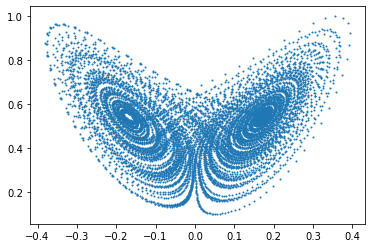

In [5]:
plt.scatter(randpts[:,0],randpts[:,2],s = 1)
#plt.scatter(Voronoi_centers[:,0],Voronoi_centers[:,2])

In [6]:
def Lorenz_vec(x):
    dx = 10 * (x[:,1] - x[:,0])
    dy = x[:,0] * (28 - x[:,2]) - x[:,1]
    dz = x[:,0] * x[:,1] - (8/3) * x[:,2]
    return torch.cat((dx.reshape(len(x),1),dy.reshape(len(x),1),dz.reshape(len(x),1)),dim = 1)

In [7]:
torch.manual_seed(100000)
net1 = nn.Sequential(
            nn.Linear(3, 100),
            nn.Tanh(),
            nn.Linear(100, 100),
            nn.Tanh(),
            nn.Linear(100, 100),
            nn.Tanh(),
            nn.Linear(100, 3))

optimizer1 = optim.Adam(net1.parameters(),lr = 1e-3)
# optimizer2 = optim.Adam(net2.parameters(),lr = 1e-3)
# net2.train()
N_iters = 5000

net1.train()
loss1 = []
# loss2 = []
#invert_variables = [0,1,2]


Iteration 0, Loss(Ours): 0.41583412885665894


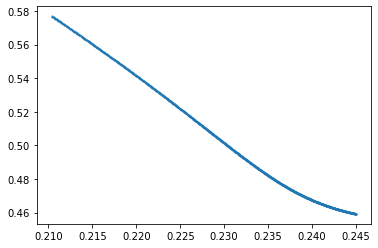

Iteration 500, Loss(Ours): 0.0186013150960207
Iteration 1000, Loss(Ours): 0.00500037707388401
Iteration 1500, Loss(Ours): 0.0071834237314760685
Iteration 2000, Loss(Ours): 0.006433306727558374
Iteration 2500, Loss(Ours): 0.006463755387812853
Iteration 3000, Loss(Ours): 0.005678344517946243
Iteration 3500, Loss(Ours): 0.004732151050120592
Iteration 4000, Loss(Ours): 0.00610395660623908
Iteration 4500, Loss(Ours): 0.0055061024613678455


In [8]:
for i in range(N_iters):
    # Zero gradients for each optimizer
    optimizer1.zero_grad()
    # optimizer2.zero_grad()
    
    # Update for net1 (Ulam)
    # net1_randpts = net1(randpts) #parametrize the map
    net1_randpts = randpts

    V_field = Lorenz_vec(net1_randpts*M_scale)/M_scale
    V_field = net1(net1_randpts)
    #V_field[:,invert_variables] = net1(net1_randpts)[:,invert_variables]
    net1_randpts = net1_randpts+dt* V_field
    U_net = Ulam(randpts,net1_randpts)
    #im_net = invariant_measure(U_net)
    #L1 = torch.linalg.matrix_norm(U_net - U_true,ord = 'fro')
    #L1 = torch.linalg.norm(im_net - im_true, dtype=torch.float32)
    L1 = ColumnOTLoss.apply(U_net)
    L1.backward()
    
    optimizer1.step()
    loss1.append(L1.item())  # Directly use .item() for scalar value

    # with torch.no_grad():
    if i % 500 == 0:
        print(f'Iteration {i}, Loss(Ours): {L1.item()}')
    #         if L1.item() < 0.02  * initial_L1:
    #             print(f"Early stopping at iteration {i}, Loss: {L1.item()}")
    #             break
        
    # Visualization every 500 iterations
    if i % 5000 == 0:
        x1 = torch.tensor(randpts[0], dtype=torch.float).reshape(1, 3)
        # x2 = x1
        vals1= [x1.detach().numpy().flatten()]
        for _ in range(int(1e3)-1):
            V_field = Lorenz_vec(x1*M_scale)/M_scale
            #V_field[:,invert_variables] = net1(x1)[:,invert_variables]
            V_field= net1(x1)
            x1 = x1 + V_field*dt
                
            vals1.append(x1.detach().numpy().flatten())

        
        vals1= np.array(vals1)
        plt.scatter(vals1[:, 0], vals1[:, 2], s=1)
        plt.show()
        # plt.scatter(vals2[:, 0], vals2[:, 1], s=1)
        # plt.show()


Iteration 0, Loss(Ours): 0.00018212880240753293


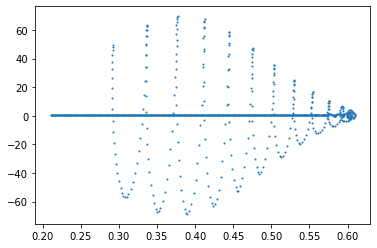

Iteration 1000, Loss(Ours): 2.9783577701891772e-05


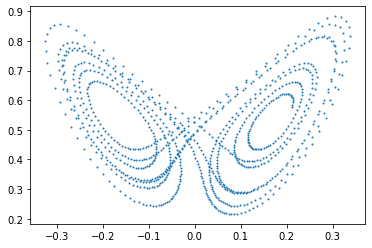

Iteration 2000, Loss(Ours): 8.157800948538352e-06


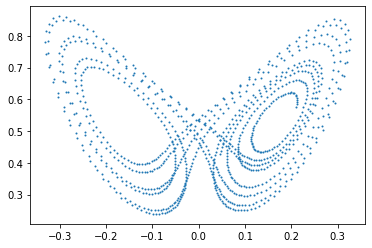

Iteration 3000, Loss(Ours): 1.0766332707135007e-05


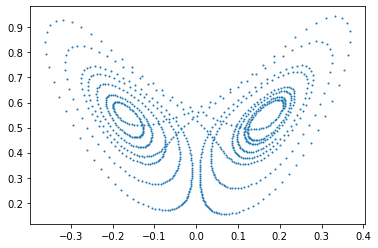

Iteration 4000, Loss(Ours): 6.913888682902325e-06


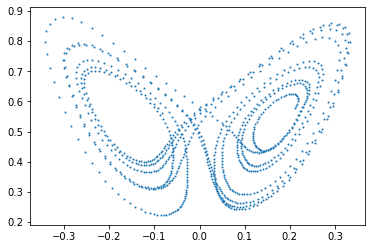

In [9]:
torch.manual_seed(100000)
net2 = nn.Sequential(
            nn.Linear(3, 100),
            nn.Tanh(),
            nn.Linear(100, 100),
            nn.Tanh(),
            nn.Linear(100, 100),
            nn.Tanh(),
            nn.Linear(100, 3))
optimizer2 = optim.Adam(net2.parameters(),lr = 1e-3)
net2.train()
loss2 = []
invert_variables = [0]
for i in range(N_iters):
    # Zero gradients for each optimizer
    optimizer2.zero_grad()
    net2_randpts = randpts

    V_field2 = Lorenz_vec(net2_randpts*M_scale)/M_scale
    V_field2[:,invert_variables] = net2(net2_randpts)[:,invert_variables]
    #V_field2 = net2(net2_randpts)
    net2_randpts = net2_randpts+dt* V_field2
    U_net = Ulam(randpts,net2_randpts)
    im_net = invariant_measure(U_net)
    L2 = W2Loss.apply(im_net)
    L2.backward()
    optimizer2.step()
    loss2.append(L2.item())  # Directly use .item() for scalar value

    # Logging
    if i % 1000 == 0:
        print(f'Iteration {i}, Loss(Ours): {L2.item()}')#, Loss(Pointwise): {L2.item()}')
        x2 = torch.tensor(randpts[0], dtype=torch.float).reshape(1, 3)

        vals2= [x2.detach().numpy().flatten()]
        for _ in range(int(1e3)-1):
            V_field2 = Lorenz_vec(x2*M_scale)/M_scale
            V_field2[:,invert_variables] = net2(x2)[:,invert_variables]
            x2 = x2 + V_field2*dt
                
            vals2.append(x2.detach().numpy().flatten())

        
        vals2= np.array(vals2)
        plt.scatter(vals2[:, 0], vals2[:, 2], s=1)
        plt.show()
    # Visualization every 500 iterations
    #if i % 5000 == 0:


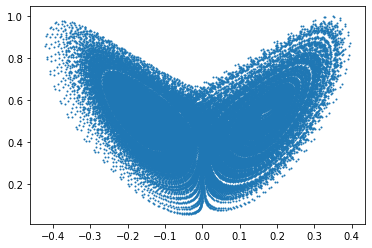

In [10]:
x1 = torch.tensor(randpts[0], dtype=torch.float).reshape(1, 3)
vals1 = [x1.detach().numpy().flatten()]
for _ in range(simulation_t-1):

    
    V_field = net1(x1)
    x1 = x1 + V_field*dt
    vals1.append(x1.detach().numpy().flatten())
vals1 = np.array(vals1)
plt.scatter(vals1[:, 0], vals1[:, 2], s=1)
plt.show()

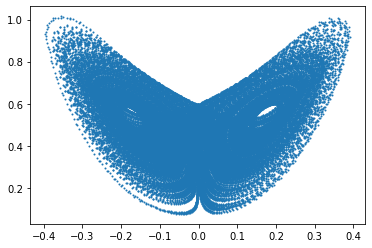

In [11]:
x2 = torch.tensor(randpts[0], dtype=torch.float).reshape(1, 3)
vals2 = [x2.detach().numpy().flatten()]
for _ in range(simulation_t-1):

    V_field2 = Lorenz_vec(x2*M_scale)/M_scale
    V_field2[:,invert_variables] = net2(x2)[:,invert_variables]
    x2 = x2 + V_field2*dt
    vals2.append(x2.detach().numpy().flatten())
vals2 = np.array(vals2)
plt.scatter(vals2[:, 0], vals2[:, 2], s=1)
plt.show()

In [12]:

GT = traj(int(simulation_t), M_scale* randpts[0])

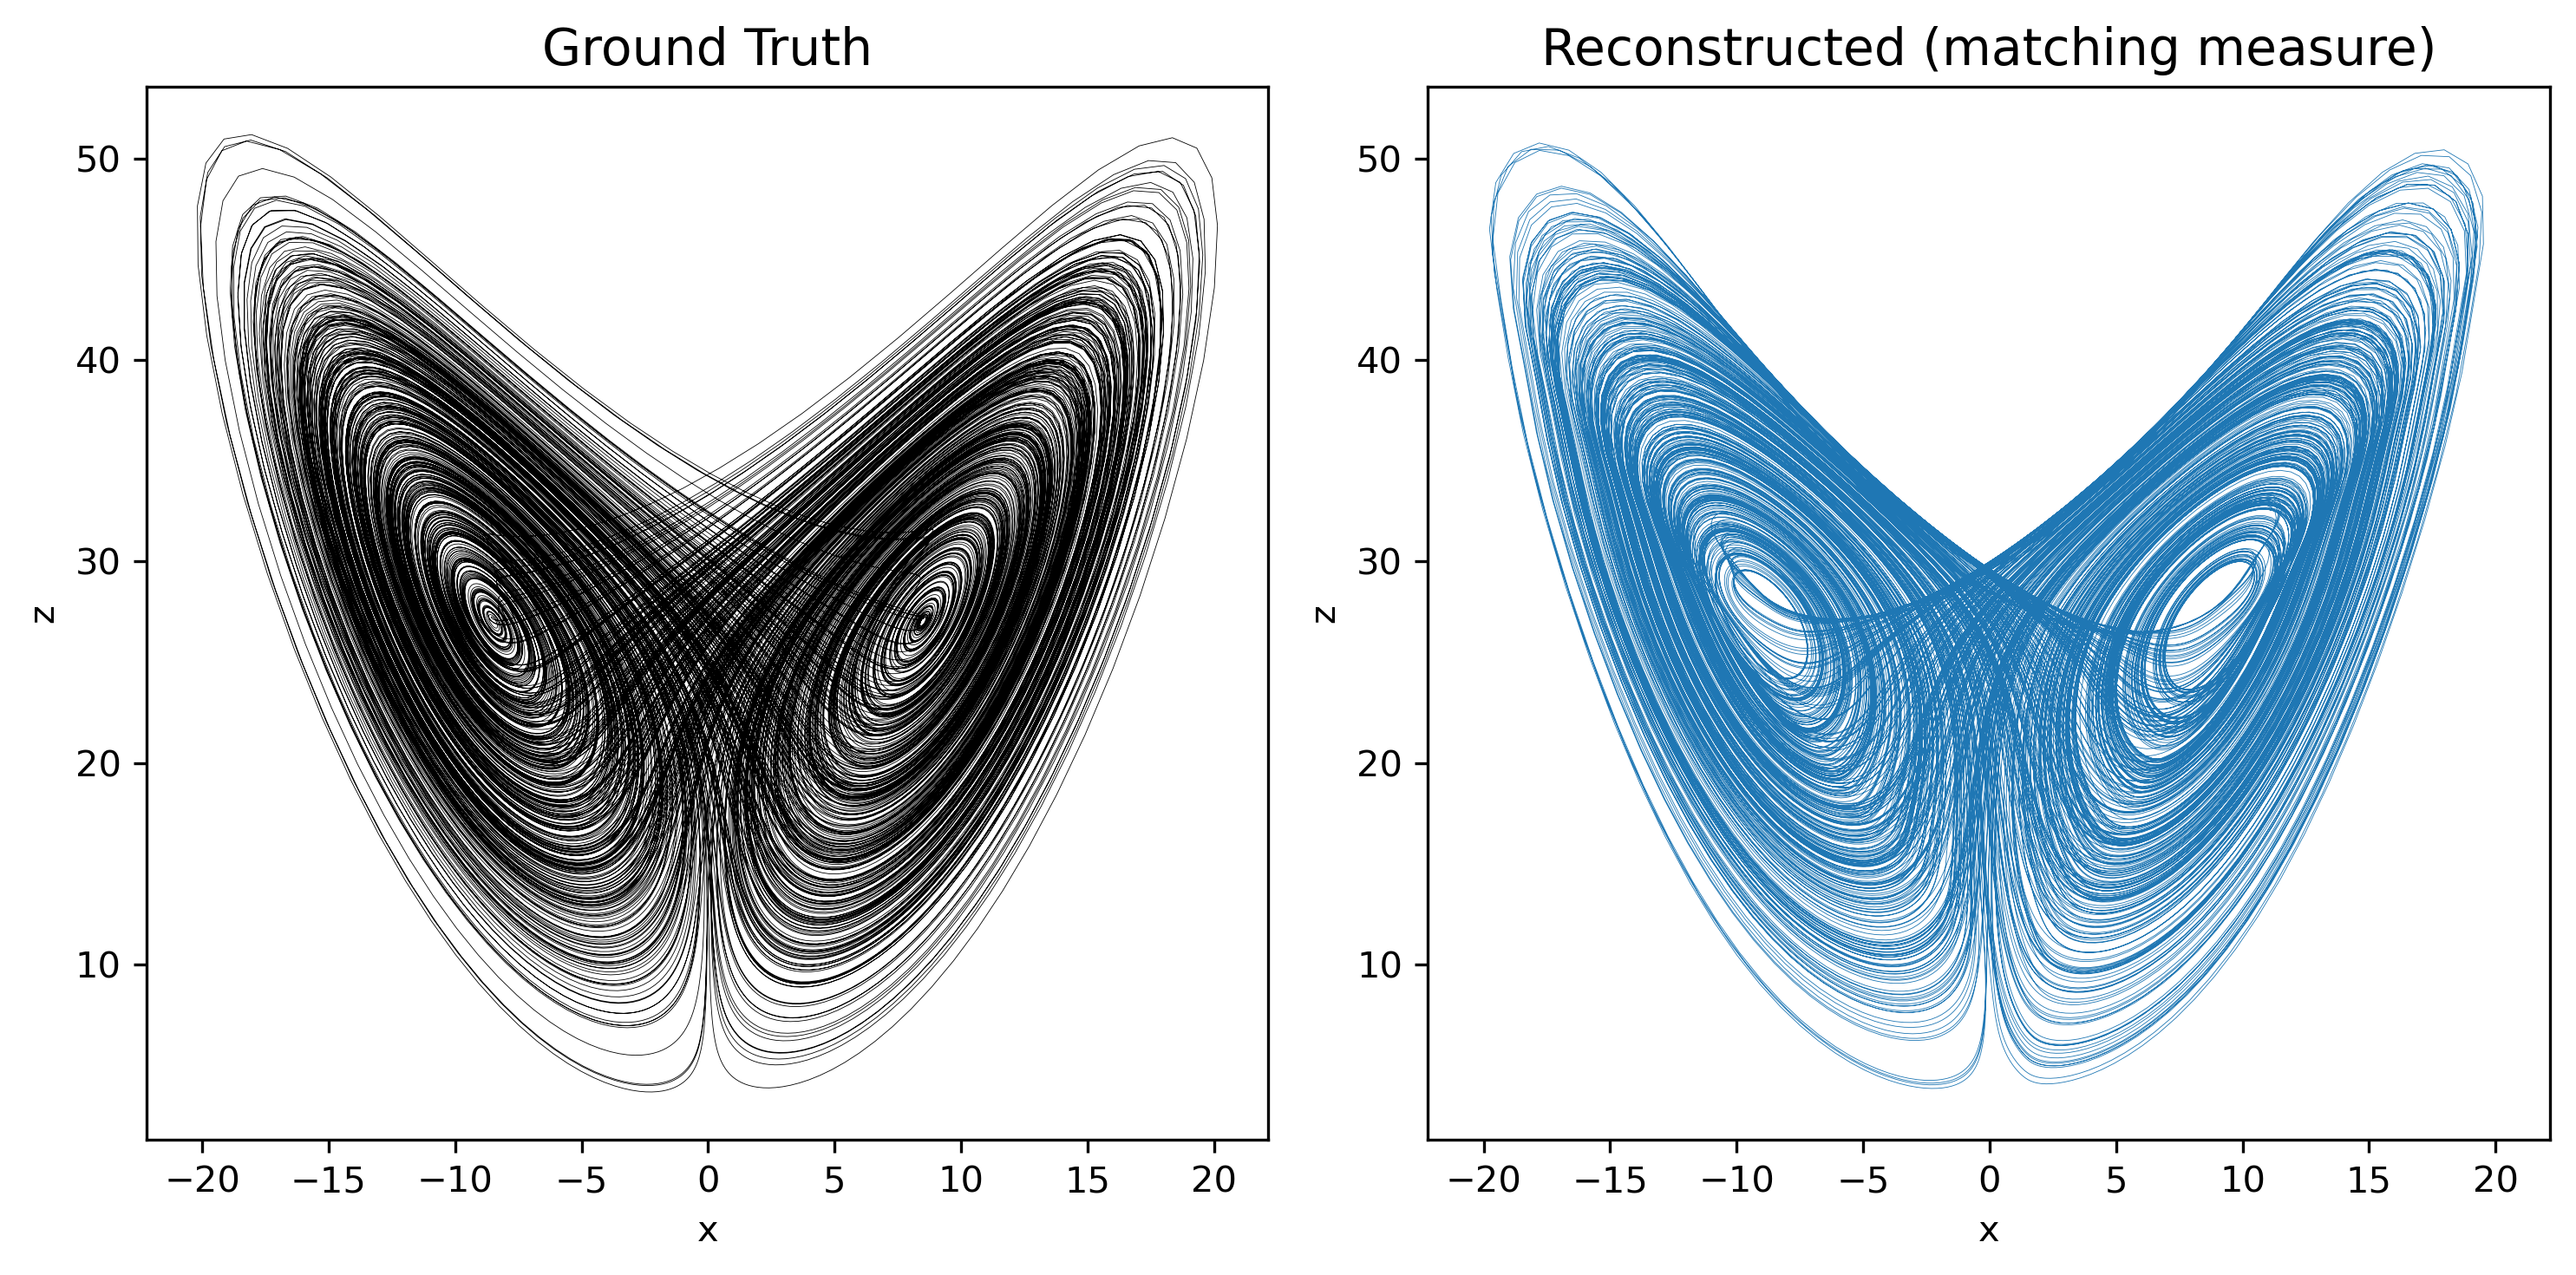

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5), dpi=300)

# First plot: Ground Truth
axes[0].plot(GT[:, 0], GT[:, 2], label="Ground Truth", linewidth=0.2, c="black")
axes[0].set_xlabel("x")
axes[0].set_ylabel("z")
axes[0].set_title("Ground Truth",fontsize = 14)

# Save axis limits
xlims = axes[0].get_xlim()
ylims = axes[0].get_ylim()

# Second plot: Reconstructed Trajectory 
axes[1].plot(M_scale * vals2[:, 0], M_scale * vals2[:, 2], linewidth=0.2)
axes[1].set_xlabel("x")
axes[1].set_ylabel("z")
axes[1].set_title("Reconstructed (matching measure)",fontsize = 14)
axes[1].set_xlim(xlims)
axes[1].set_ylim(ylims)

plt.tight_layout()
plt.show()


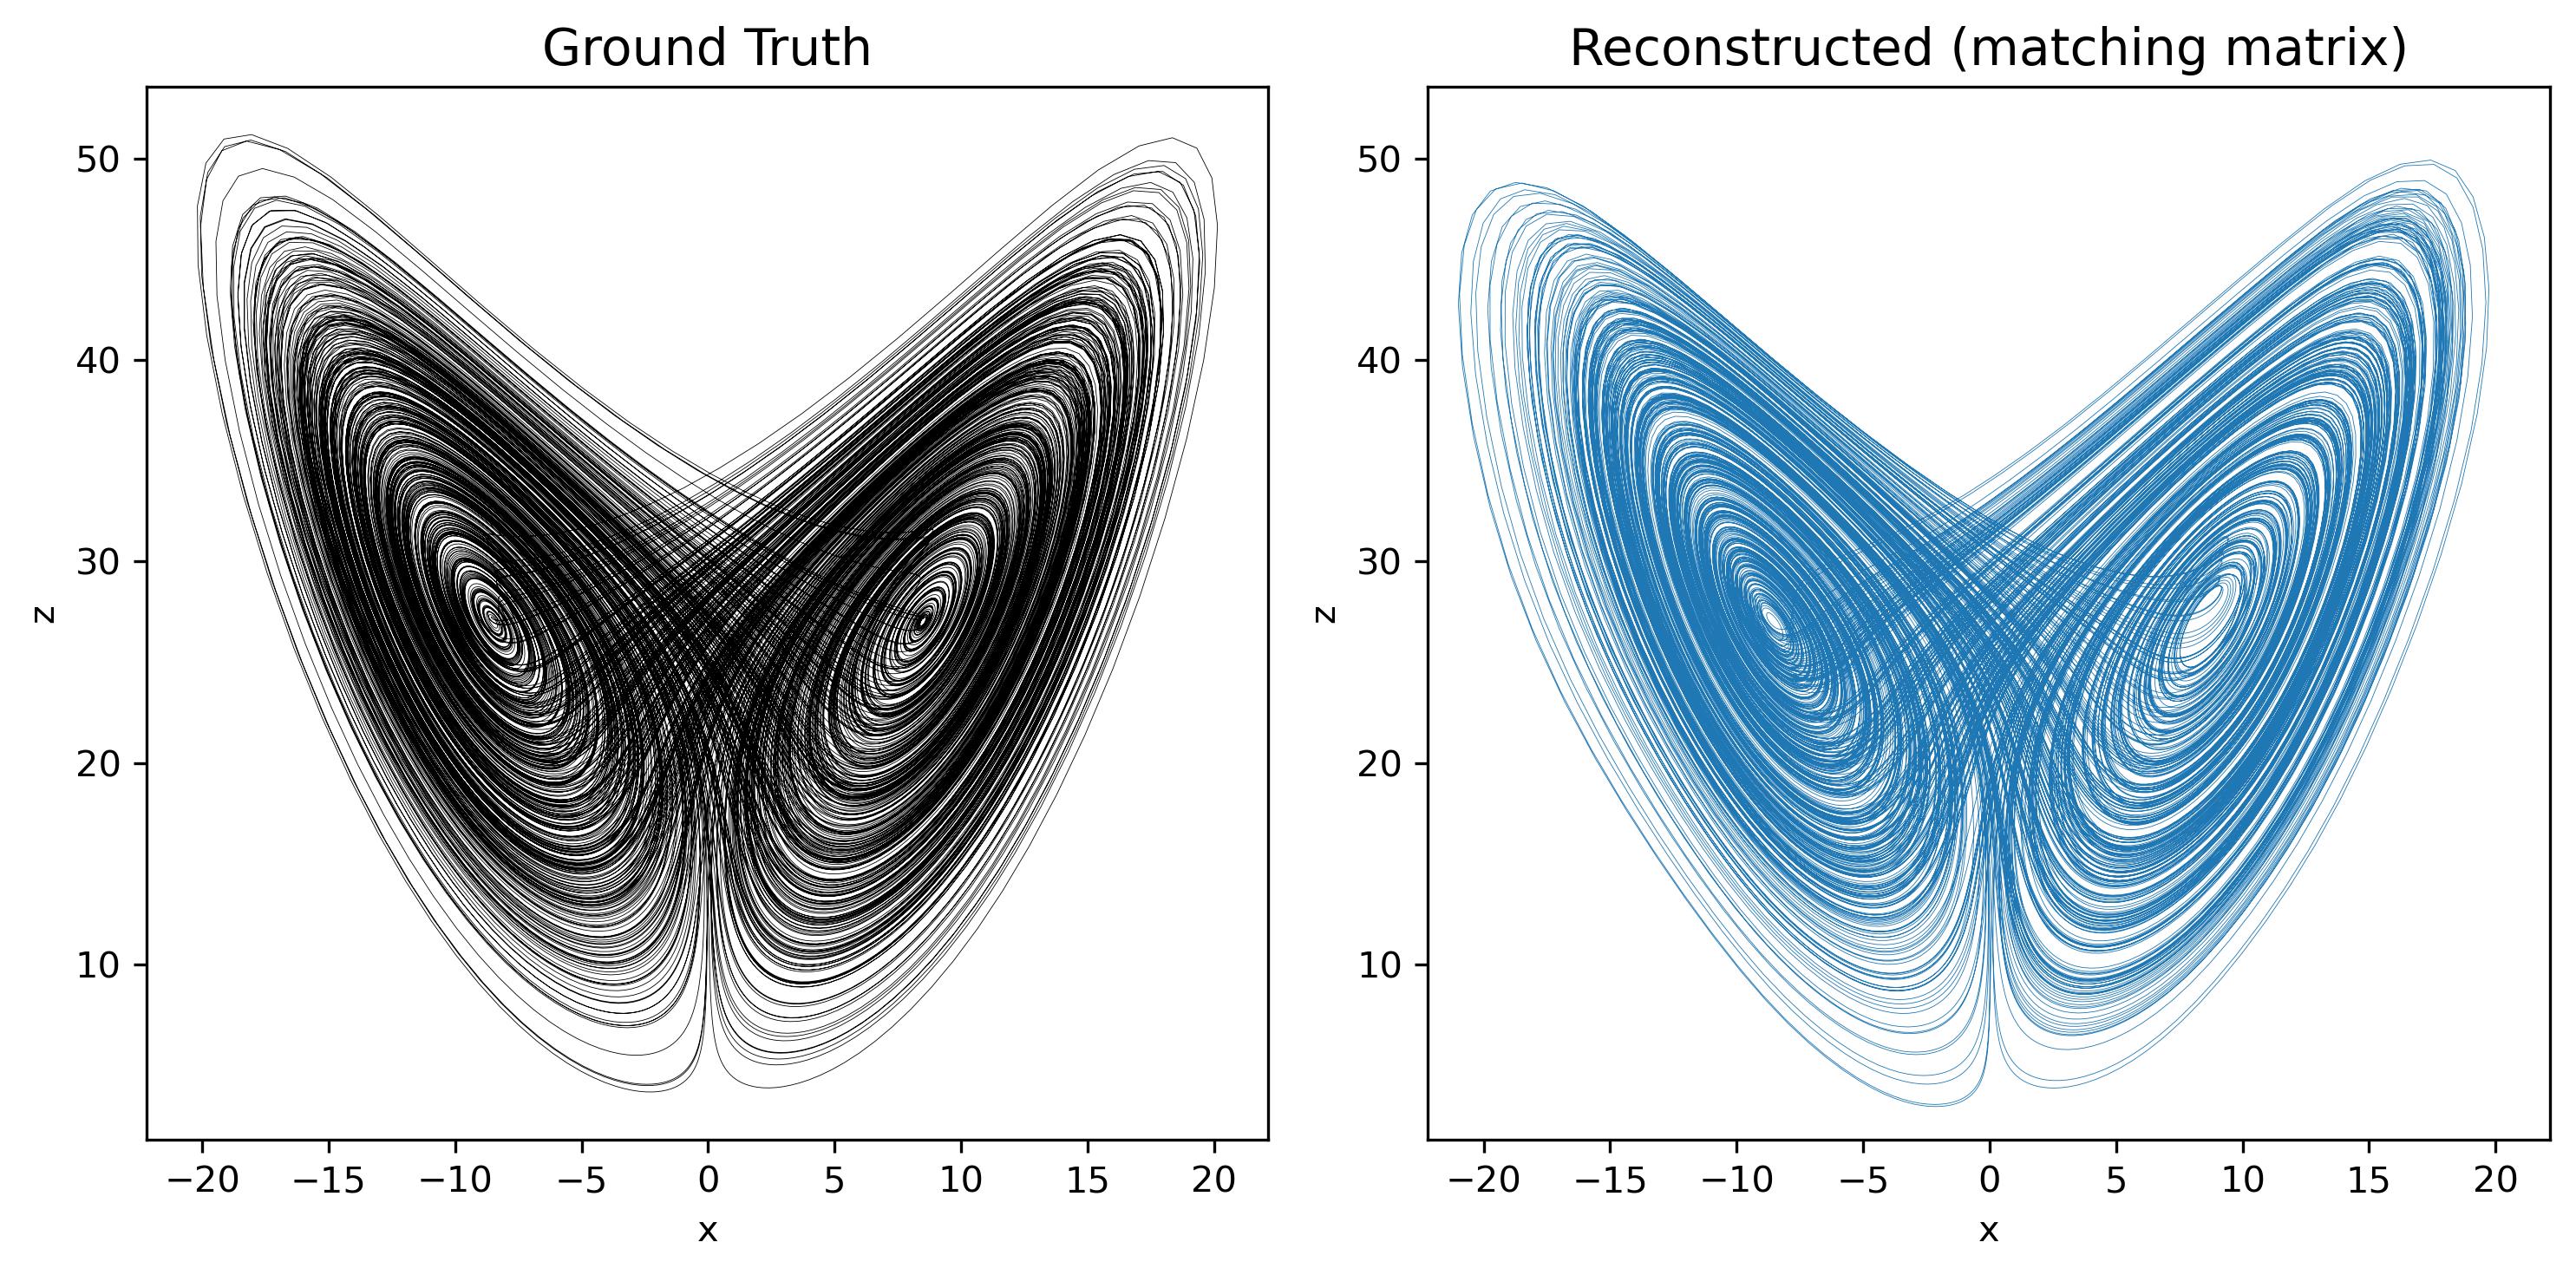

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5), dpi=300)

# First plot: Ground Truth
axes[0].plot(GT[:, 0], GT[:, 2], label="Ground Truth", linewidth=0.2, c="black")
axes[0].set_xlabel("x")
axes[0].set_ylabel("z")
axes[0].set_title("Ground Truth",fontsize = 14)

# Save axis limits
xlims = axes[0].get_xlim()
ylims = axes[0].get_ylim()

# Second plot: Reconstructed Trajectory (matching matrix)
axes[1].plot(M_scale * vals1[:, 0], M_scale * vals1[:, 2], linewidth=0.2)
axes[1].set_xlabel("x")
axes[1].set_ylabel("z")
axes[1].set_title("Reconstructed (matching matrix)",fontsize = 14)
axes[1].set_xlim(xlims)
axes[1].set_ylim(ylims)

plt.tight_layout()
plt.show()